Tugas Praktikum - Pra pengolahan data Wisconsin Breast Cancer.

Langkah: pisahkan variabel berguna/tidak -> encoding "diagnosis" ->
standardisasi seluruh kolom numerik.

In [1]:
# Shim: notebook tidak punya __file__, kode ini warisan script .py.
import os
__file__ = os.path.abspath("wbc_preprocessing.ipynb")
print("base:", os.path.dirname(__file__))

base: C:\code\pemmes26\js02-pemahaman-data-dan-pra-pengolahan-data\tugas


In [2]:
from pathlib import Path

import matplotlib

import matplotlib.pyplot as plt
import pandas as pd
from sklearn.preprocessing import LabelEncoder, StandardScaler

BASE = Path(__file__).resolve().parent
DATA = BASE.parent / "data" / "wbc.csv"
OUT = BASE / "output"
OUT.mkdir(parents=True, exist_ok=True)

df = pd.read_csv(DATA)
print("=== Data mentah ===", df.shape)
print("kolom:", list(df.columns[:3]), "...", list(df.columns[-3:]))

=== Data mentah === (569, 33)
kolom: ['id', 'diagnosis', 'radius_mean'] ... ['symmetry_worst', 'fractal_dimension_worst', 'Unnamed: 32']


In [3]:
# ---------- 1. Pisahkan variabel terpakai / tidak terpakai ----------
drop_cols = [c for c in df.columns if c.startswith("Unnamed")]
drop_cols.append("id")  # id hanya identitas, tidak punya daya prediksi
print("\nKolom dibuang:", drop_cols)
for c in drop_cols:
    print(f" - {c}: nunique={df[c].nunique()}")

df = df.drop(columns=drop_cols)
print("\nDimensi setelah pemisahan:", df.shape)
print("tipe data:", df.dtypes.value_counts().to_dict())
print("missing value total:", int(df.isnull().sum().sum()))


Kolom dibuang: ['Unnamed: 32', 'id']
 - Unnamed: 32: nunique=0
 - id: nunique=569

Dimensi setelah pemisahan: (569, 31)
tipe data: {dtype('float64'): 30, dtype('O'): 1}
missing value total: 0


In [4]:
# ---------- 2. Encoding diagnosis ----------
le = LabelEncoder()
print("\nSebelum encoding:", df["diagnosis"].value_counts().to_dict())
df["diagnosis"] = le.fit_transform(df["diagnosis"])
mapping = {k: int(v) for k, v in zip(le.classes_, le.transform(le.classes_))}
print("Mapping diagnosis:", mapping, "(B=jinak, M=ganas)")
print("Setelah encoding:", df["diagnosis"].value_counts().sort_index().to_dict())
print("proporsi ganas: %.2f%%" % (df["diagnosis"].mean() * 100))


Sebelum encoding: {'B': 357, 'M': 212}
Mapping diagnosis: {'B': 0, 'M': 1} (B=jinak, M=ganas)
Setelah encoding: {0: 357, 1: 212}
proporsi ganas: 37.26%


In [5]:
# ---------- 3. Standardisasi semua kolom numerik ----------
num_cols = [c for c in df.columns if c != "diagnosis"]
sebelum = df[num_cols].agg(["mean", "std"]).T
std = StandardScaler()
df[num_cols] = std.fit_transform(df[num_cols])
sesudah = df[num_cols].agg(["mean", "std"]).T

cek = sebelum.join(sesudah, lsuffix="_sebelum", rsuffix="_sesudah")
print("\n=== Ringkasan standardisasi (5 kolom pertama) ===")
print(cek.head().round(4).to_string())
print("\nJumlah fitur distandardisasi:", len(num_cols))
print("max |mean| setelah scaling: %.2e" % df[num_cols].mean().abs().max())
print("rentang std setelah scaling: [%.6f, %.6f]"
      % (df[num_cols].std(ddof=0).min(), df[num_cols].std(ddof=0).max()))
assert df[num_cols].mean().abs().max() < 1e-9
assert abs(df[num_cols].std(ddof=0) - 1).max() < 1e-9

print("\n5 data teratas hasil akhir:")
print(df.head().round(4).to_string())
print("\nDimensi akhir:", df.shape)

df.to_csv(OUT / "wbc_preprocessed.csv", index=False)
cek.round(4).to_csv(OUT / "ringkasan_scaling.csv")


=== Ringkasan standardisasi (5 kolom pertama) ===
                 mean_sebelum  std_sebelum  mean_sesudah  std_sesudah
radius_mean           14.1273       3.5240          -0.0       1.0009
texture_mean          19.2896       4.3010           0.0       1.0009
perimeter_mean        91.9690      24.2990          -0.0       1.0009
area_mean            654.8891     351.9141          -0.0       1.0009
smoothness_mean        0.0964       0.0141          -0.0       1.0009

Jumlah fitur distandardisasi: 30
max |mean| setelah scaling: 8.37e-16
rentang std setelah scaling: [1.000000, 1.000000]

5 data teratas hasil akhir:
   diagnosis  radius_mean  texture_mean  perimeter_mean  area_mean  smoothness_mean  compactness_mean  concavity_mean  concave points_mean  symmetry_mean  fractal_dimension_mean  radius_se  texture_se  perimeter_se  area_se  smoothness_se  compactness_se  concavity_se  concave points_se  symmetry_se  fractal_dimension_se  radius_worst  texture_worst  perimeter_worst  area_wors

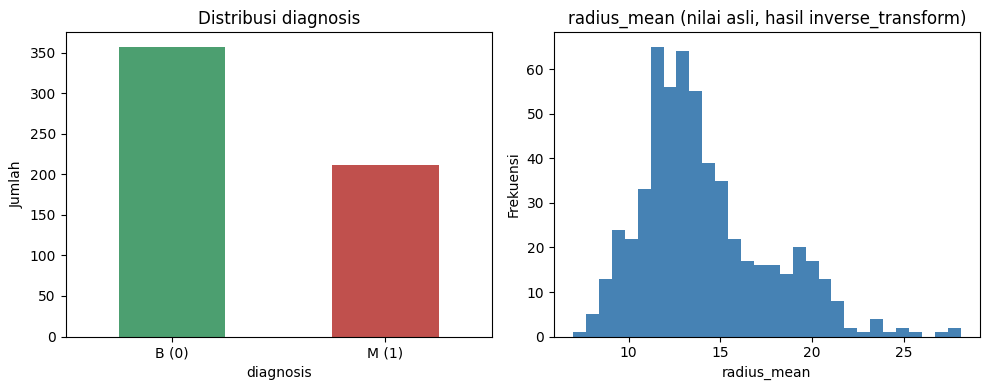

In [6]:
# ---------- Visualisasi ----------
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
df["diagnosis"].value_counts().sort_index().plot(
    kind="bar", ax=axes[0], color=["#4c9f70", "#c0504d"]
)
axes[0].set_xticklabels(["B (0)", "M (1)"], rotation=0)
axes[0].set_title("Distribusi diagnosis")
axes[0].set_ylabel("Jumlah")

axes[1].hist(std.inverse_transform(df[num_cols])[:, 0], bins=30, color="steelblue")
axes[1].set_title("radius_mean (nilai asli, hasil inverse_transform)")
axes[1].set_xlabel("radius_mean")
axes[1].set_ylabel("Frekuensi")
fig.tight_layout()
fig.savefig(OUT / "wbc_hasil.png", dpi=110)

In [7]:
# Fitur paling berkorelasi dengan diagnosis (informasi pendukung)
korelasi = df.corr()["diagnosis"].drop("diagnosis").sort_values(key=abs, ascending=False)
print("\n5 fitur paling berkorelasi dengan diagnosis:")
print(korelasi.head().round(3).to_string())


5 fitur paling berkorelasi dengan diagnosis:
concave points_worst    0.794
perimeter_worst         0.783
concave points_mean     0.777
radius_worst            0.776
perimeter_mean          0.743
